In [1]:
from rdkit import Chem
from rdkit.Chem.Draw import MolsToGridImage
from rdkit.Chem import rdDepictor
from rdkit import IPythonConsole
from rdkit.Chem import EnumerateStereoisomers
from rdkit.Chem.MolStandardize import rdMolStandardize

In [2]:
IPythonConsole.ipython_useSVG = True
rdDepictor.SetPreferCoordGen(True)

In [3]:
smi_1 = "F[C@](Cl)(Br)c1ccc(cc1)C(F)(Cl)Br"
mol_1 = Chem.MolFromSmiles(smi_1)
smi_2 = "F[C@@](Cl)(Br)c1ccc(cc1)C(F)(Cl)Br"
mol_2 = Chem.MolFromSmiles(smi_2)

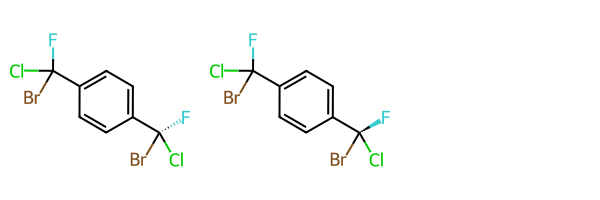

In [4]:
mol_list = [mol_1, mol_2]
MolsToGridImage(mol_list)

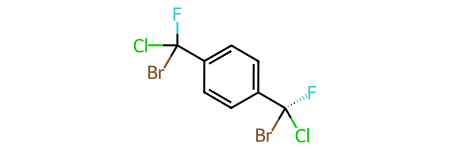

In [5]:
mol_1

In [6]:
EnumerateStereoisomers.EnumerateStereoisomers(mol_1)

<generator object EnumerateStereoisomers at 0x127d30580>

In [7]:
mol_1_isomer_list = [x for x in EnumerateStereoisomers.EnumerateStereoisomers(mol_1)]
mol_1_isomer_list

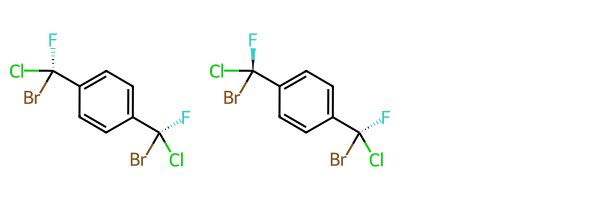

In [8]:
MolsToGridImage(mol_1_isomer_list)

In [9]:
IPythonConsole.drawOptions.addStereoAnnotation = True

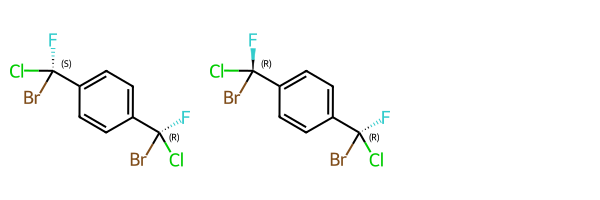

In [10]:
MolsToGridImage(mol_1_isomer_list)

In [11]:
Chem.FindMolChiralCenters(mol_1,force=True,includeUnassigned=True,useLegacyImplementation=True)

[(1, 'R'), (10, '?')]

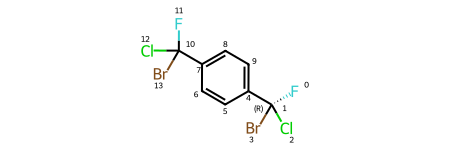

In [12]:
IPythonConsole.drawOptions.addAtomIndices = True
mol_1

In [13]:
for m in EnumerateStereoisomers.EnumerateStereoisomers(mol_1):
    print(Chem.FindMolChiralCenters(m,force=True,includeUnassigned=True,useLegacyImplementation=False))

[(1, 'R'), (10, 'S')]
[(1, 'R'), (10, 'R')]


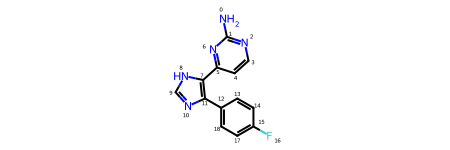

In [14]:
kinase_smi = "Nc1nccc(n1)-c1[nH]cnc1-c1ccc(F)cc1"
kinase_mol = Chem.MolFromSmiles(kinase_smi)
kinase_mol

In [15]:
tautomer_enumerator = rdMolStandardize.TautomerEnumerator()

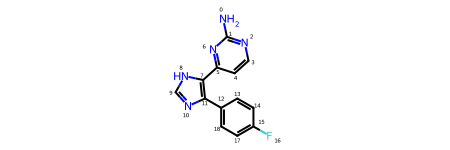

In [16]:
canonical_tautomer_mol = tautomer_enumerator.Canonicalize(kinase_mol)
canonical_tautomer_mol

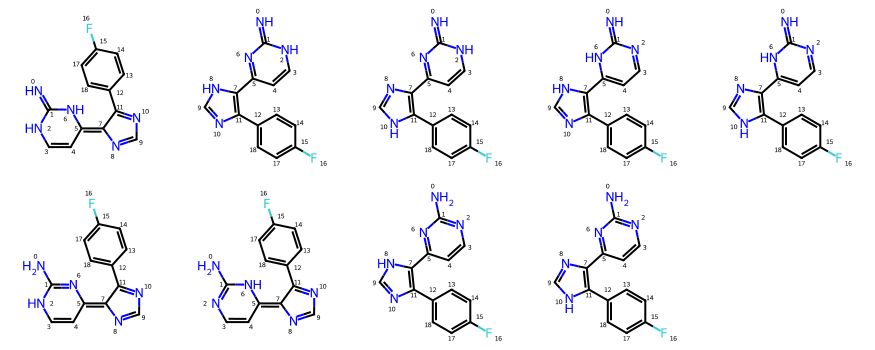

In [17]:
tautomer_list = [x for x in tautomer_enumerator.Enumerate(kinase_mol)]
MolsToGridImage(tautomer_list, molsPerRow=5,subImgSize=(175, 175))